# Binary classifications
Examples of binary classifications based on the binary_classification subpackage.

## Table of contents
* [Background galaxy selection, using LinearClassification](#sec1)
* [Write to file and load from file](#sec2)
* [Complex galaxy selection, using GridClassification](#sec3)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from fomoz.data import (
    Dataset,
    SelectionDefinition,
)

from fomoz.binary_classification import (
    LinearClassification,
    GridClassification,
    Classifier,
    PlotCalibration,
)

## Background galaxy selection, using LinearClassification <a class="anchor" id="sec1"></a>

Calibration of a simple background galaxy selection, based on $gri$ photometry.\
The redshift limits considered in this case are: 0.2, 0.3, 0.4, 0.5, 0.6.\
The parameters of the optimal color conditions are automatically interpolated.

In [2]:
# Load the reference sample, having the entries
# 'g', 'r', 'i', 'redshift'
ref_sample = pd.read_csv('./../data/input/reference.csv', comment='#')

# Dataset
bands = ['g', 'r', 'i']

dataset = Dataset(
    ref_sample,
    bands,
    z_gal_string='redshift',  # redshift string
    missing_data=-99,  # non-detection value
    PDZs=None,  # values of the redshift PDF for each object in ref_sample. Not used here
    PDZ_x=None,
    weights=None,
)

# SelectionDefinition
z_l = [0.2, 0.3, 0.4, 0.5, 0.6]  # lower redshift limits

selection = SelectionDefinition(
    z_l,
    is_zlim_lower=True,  # if True, z_l is a lower limit
    additional_rules=None,
)

# Calibrate the selection
P_threshold = 0.97  # purity threshold

calib_linear = LinearClassification(dataset, selection, P_threshold)
calib_linear.process()


Running the linear color cut calibration...


Deriving bootstrap errors: 100%|██████████| 1000/1000 [00:03<00:00, 256.32it/s]

Linear cut calibration complete.


In [3]:
# Print the metrics
for i in range(len(z_l)):
    print(f"\nz_l = {z_l[i]}")
    print(f"Completeness: {calib_linear.C[i]} +- {calib_linear.C_std[i]}")
    print(f"Purity: {calib_linear.P[i]} +- {calib_linear.P_std[i]}")
    print(f"Failure rate: {calib_linear.F[i]} +- {calib_linear.F_std[i]}")


z_l = 0.2
Completeness: 0.8362327534493101 +- 0.0052696035849209575
Purity: 0.9707520891364902 +- 0.0025116807981771594
Failure rate: 0.5502183406113537 +- 0.03197519766071825

z_l = 0.3
Completeness: 0.793812292358804 +- 0.005918786515283175
Purity: 0.9707973590655155 +- 0.002647497980834023
Failure rate: 0.2777777777777778 +- 0.021664293409338186

z_l = 0.4
Completeness: 0.7976584934835432 +- 0.0060596629280474925
Purity: 0.9706989247311828 +- 0.002770965247522209
Failure rate: 0.155049786628734 +- 0.013841198058361707

z_l = 0.5
Completeness: 0.8141115799343648 +- 0.005963639796623502
Purity: 0.970653996646171 +- 0.0026769493082581955
Failure rate: 0.10892116182572614 +- 0.009693986268332691

z_l = 0.6
Completeness: 0.8018606990193613 +- 0.006256893428772992
Purity: 0.9704808277541084 +- 0.0028544453841608877
Failure rate: 0.07741420590582601 +- 0.007410159892385222


In [4]:
# ------------- Classifier -------------

# Apply the calibrated selection to an external test sample, using the Classifier class.
# For simplicity, we use the reference catalog as the test sample.
test_sample = pd.read_csv('./../data/input/reference.csv', comment='#')

# Create a Classifier instance
color_selection = Classifier()

# Load the calibrated selection's parameters
color_selection.load_parameters(calib_linear)


# Apply the selection to test_sample.
# For LinearClassification selections, the user can pass any redshift limit value
# within [min(z_l), max(z_l)]: the color cut parameters are interpolated over this range.

z_l_test = 0.45  # this redshift limit value can be either a float or an array-like
color_selection.process(z_l_test, test_sample, missing_data=-99)

# Get the mask to be applied to test_sample.
# Its shape is (len(z_l_test), len(test_sample)).
mask = color_selection.mask

test_sample_selected = test_sample[mask[0]]

print(f"{len(test_sample)} objects in the test sample.")
print(f"{len(test_sample_selected)} objects were selected in the test sample.")

LinearClassification parameters successfully loaded.
5230 objects in the test sample.
3638 objects were selected in the test sample.


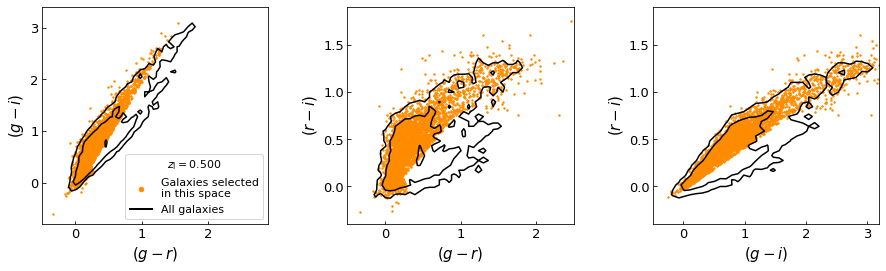

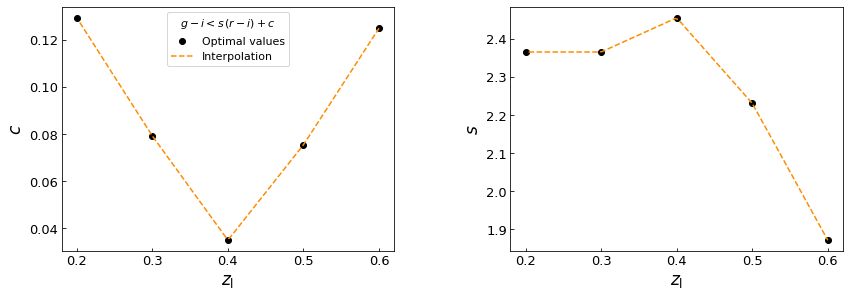

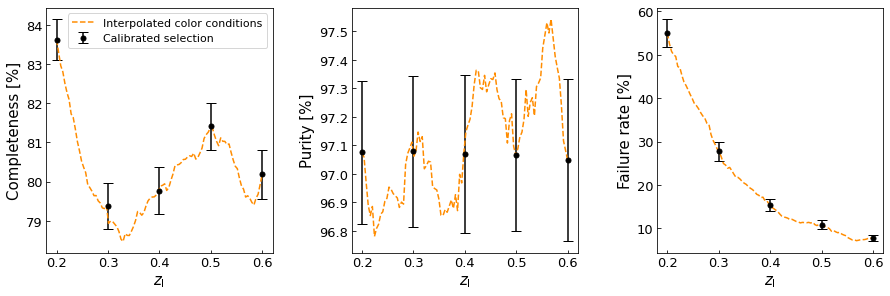

In [5]:
# ------------- PlotCalibration -------------

# Create a PlotCalibration instance
# The Classifier object defined above is passed
plotter = PlotCalibration(color_selection, dataset)

# Color-color spaces
plotter.plot_all_color_distributions(
    3,  # z_l index, i.e. the index, i, indicating the i-th value of the z_l variable defined above
    plot_selection_criteria=False,
    plot_all_objects="contour",
    plot_all_selected_objects=None,
    plot_selected_objects="scatter",
    figsize=(15, 4),
    xlim=[(-0.5, 2.9), (-0.5, 2.5), (-0.5, 3.2)],
    ylim=[(-0.8, 3.4), (-0.4, 1.9), (-0.4, 1.9)],
    legend_fontsize=11,
    color_selected_objects='darkorange',
)

# Plot the parameters of one of the optimal color conditions.
# The complete list of color conditions can be obtained through the get_keys() method of LinearClassification
all_condition_keys = calib_linear.get_keys()
zl_interp = np.linspace(min(z_l), max(z_l), 100)

plotter.plot_linear_cut_parameters(
    all_condition_keys[13], interp_points=zl_interp, loclegend='upper center'
)

# Metrics (completeness, purity, failure rate)
plotter.load_metrics(calib_linear)

plotter.plot_all_metrics(
    plot_style="errorbar",
    show_legend=True,
    legend_fontsize=11,
    interp_points=zl_interp,
)

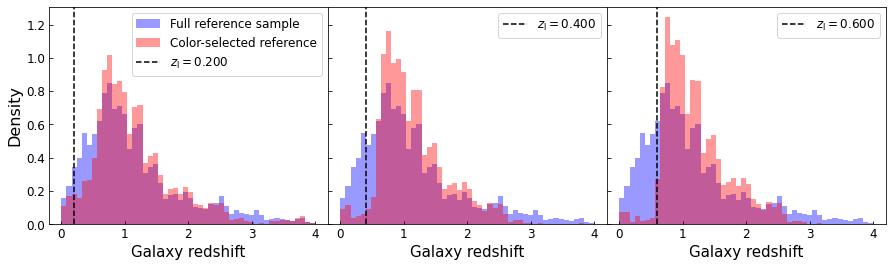

In [6]:
from fomoz.auxiliary.distributions import get_distribution as compute_distribution

# ----- Distributions of color-selected reference objects -----

# Compare the full reference redshift distribution with the distributions
# after applying the calibrated color selections.
# Prior weights are included. Reference PDZs are used when available.

fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'wspace': 0}, sharey=True)
ax[0].set_ylabel('Density', fontsize=16)

# Indices of the limiting redshifts passed to LinearClassification
zl_indices = [0, 2, 4]

# Common binning: 50 bins over the chosen redshift range
bin_edges = np.linspace(0.0, 4.0, 51)

# Full reference distribution, using the same weights and PDZ convention
has_pdzs = calib_linear.CDZs is not None

nz_full = compute_distribution(
    values=None if has_pdzs else calib_linear.dataset["redshift"],
    bin_edges=bin_edges,
    prior_weights=calib_linear.weights,
    classification_weights=np.ones(len(calib_linear.dataset)),
    normalize=True,
    missing_data=calib_linear.missing_data,
    CDZs=calib_linear.CDZs if has_pdzs else None,
    PDZ_x=calib_linear.PDZ_x if has_pdzs else None,
)

# Plot
for i, zl_index in enumerate(zl_indices):

    # Full reference sample
    ax[i].stairs(nz_full, bin_edges, fill=True, color='blue', alpha=0.4, label='Full reference sample' if i == 0 else None)

    # Color-selected reference sample
    nz = calib_linear.get_distribution(zl_index, "redshift", bin_edges, normalize=True)

    ax[i].stairs(nz, bin_edges, fill=True, color='red', alpha=0.4, linewidth=0, label='Color-selected reference' if i == 0 else None)

    # Limiting redshift
    ax[i].axvline(z_l[zl_index], color='k', linestyle='--', label=rf"$z_{{\rm l}}={z_l[zl_index]:.3f}$")

    ax[i].legend(loc='upper right', fontsize=12, labelspacing=0.5 if i == 0 else 0)
    ax[i].tick_params(which='both', direction='in', labelsize=12)
    ax[i].set_xlabel('Galaxy redshift', fontsize=15)

plt.show()

## Write to file and load from file <a class="anchor" id="sec2"></a>

Let's consider the linear calibration above.

In [7]:
# I/O folder
data_folder = './../data/tests/'
os.makedirs(data_folder, exist_ok=True)

# Write the selection criteria
calib_linear.write(data_folder, 'test')

# Load the selection criteria into Classifier from file
color_selection = Classifier()
color_selection.load_parameters_from_file(data_folder, 'FOMO-Z_test.yaml')

# z_l values where the selection is applied.
# Since we're considering a linear calibration (LinearClassification),
# we can make use of the interpolation between the z_l values used for calibration.
z_lim = [0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

# Apply the selection to a test sample.
# For simplicity, here we use the calibration sample as the test sample
test_sample = pd.read_csv('./../data/input/reference.csv', comment='#')

color_selection.process(
    z_lim,
    test_sample,
    missing_data=[99, -99],
)

# Get the mask
mask = color_selection.mask
shape = np.asarray(mask).shape

print(f"\nmask's shape: {shape} ({shape[0]} z_lim points, {shape[1]} objects in test_sample)\n")

# Apply the mask to test_sample
for i in range(len(z_lim)):
    selected_sample = test_sample[mask[i]]
    print(f"{len(selected_sample)} selected objects for z_l={z_lim[i]}")

LinearClassification parameters successfully loaded from file.

mask's shape: (6, 5230) (6 z_lim points, 5230 objects in test_sample)

4079 selected objects for z_l=0.25
3938 selected objects for z_l=0.3
3789 selected objects for z_l=0.35
3720 selected objects for z_l=0.4
3638 selected objects for z_l=0.45
3578 selected objects for z_l=0.5


## Complex galaxy selection, using GridClassification <a class="anchor" id="sec3"></a>

Now we want to select galaxies in the redshift range $z\in[0.5,1]$ and with magnitude $g>23$.\
For such a complex selection, we can use GridClassification.\
More general methods are implemented in the probability subpackage.

Here, we do not use the Classifier class for the sake of brevity.\
For information on how to use it, based on a GridClassification calibration, see the examples above.

In [8]:
# Load the reference sample
ref_sample = pd.read_csv('./../data/input/reference.csv', comment='#')

# Dataset
bands = ['g', 'r', 'i']
dataset = Dataset(ref_sample, bands, z_gal_string='redshift')

# SelectionDefinition
z_l = 0.5  # -> galaxies must have redshift larger than 0.5 (see also is_zlim_lower, below)

selection = SelectionDefinition(
    z_l,
    is_zlim_lower=True,  # if True, z_l is a lower limit and z_lim_opposite an upper limit
    z_lim_opposite=1.0,  # -> galaxies must have redshift lower than 1
    additional_rules=[("g", lambda g: g > 23)],  # -> galaxies must have magnitude g larger than 23
)

# Calibrate the selection
P_threshold = 0.8  # purity threshold

calib_grid = GridClassification(dataset, selection, P_threshold)
calib_grid.process()

print(f"Completeness: {calib_grid.C[0]} +- {calib_grid.C_std[0]}")
print(f"Purity: {calib_grid.P[0]} +- {calib_grid.P_std[0]}")
print(f"Failure rate: {calib_grid.F[0]} +- {calib_grid.F_std[0]}")


Running the grid color selection calibration...


Deriving bootstrap errors: 100%|██████████| 1000/1000 [00:04<00:00, 203.27it/s]

Grid calibration complete.
Completeness: 0.3952835485682201 +- 0.011262504645179885
Purity: 0.7936865839909808 +- 0.0135460374118024
Failure rate: 0.053058857639895624 +- 0.0037384881039077777


GridClassification parameters successfully loaded.


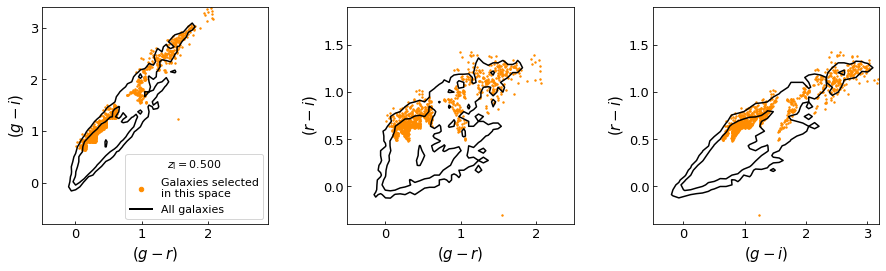

In [9]:
# Plot
color_selection = Classifier()
color_selection.load_parameters(calib_grid)

plotter = PlotCalibration(color_selection, dataset)

plotter.plot_all_color_distributions(
    0,  # z_l index, i.e. the index, i, indicating the i-th value of the z_l variable defined above
    plot_selection_criteria=False,
    plot_all_objects="contour",
    plot_all_selected_objects=None,
    plot_selected_objects="scatter",
    figsize=(15, 4),
    xlim=[(-0.5, 2.9), (-0.5, 2.5), (-0.5, 3.2)],
    ylim=[(-0.8, 3.4), (-0.4, 1.9), (-0.4, 1.9)],
    legend_fontsize=11,
    color_selected_objects='darkorange',
)